PROBLÈME 2

In [953]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
import numpy as np
from scipy.stats import norm


a. Statistiques descriptives et graphiques

In [954]:
# Lecture du fichier
df = pd.read_csv("PJM.csv")

df.columns = ["date", "price", "S_load", "Z_load"]

df["date"] = pd.to_datetime(df["date"])

# Les données sont horaires : on calcule la moyenne de chaque jour
daily = df.set_index("date").resample("D").mean()

# Afficher les 5 premières lignes pour vérifier
daily.head()

,price,S_load,Z_load
date,,,
2013-01-01,27.175540,92435.625000,11795.291667
2013-01-02,33.734351,103247.625000,12565.541667
2013-01-03,29.849249,103640.708333,12502.583333
2013-01-04,28.198551,102280.958333,12286.833333
2013-01-05,26.124395,93045.041667,11032.708333


In [955]:
# Moyenne, écart-type, min, médiane, max pour chaque série
daily.describe(percentiles=[0.5]).rename(index={"50%": "médiane"}).round(2)

,price,S_load,Z_load
count,2184.00,2184.00,2184.00
mean,30.47,91010.09,11371.25
std,14.99,11700.10,1620.30
min,8.18,67889.29,8207.33
médiane,28.54,89733.08,11075.04
max,456.76,128002.75,17829.88


In [956]:
# Enregistrer les statistiques descriptives dans un fichier Excel
stats = daily.describe(percentiles=[0.5]).rename(index={"50%": "médiane"}).round(2)
stats.to_excel("statistiques_descriptives.xlsx")

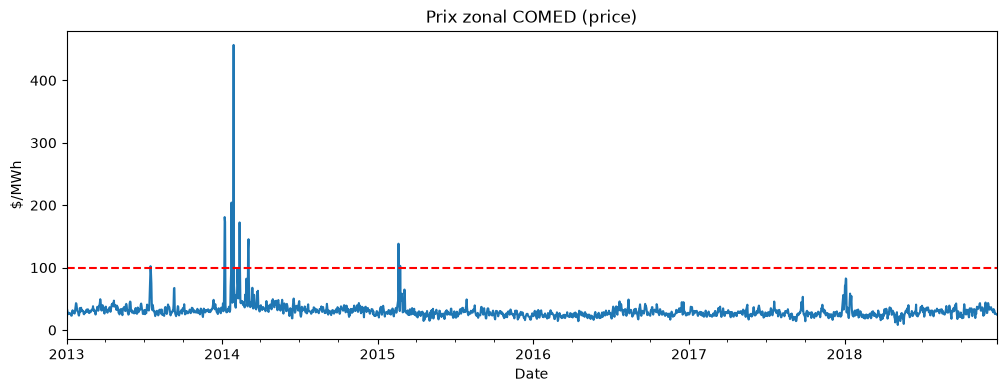

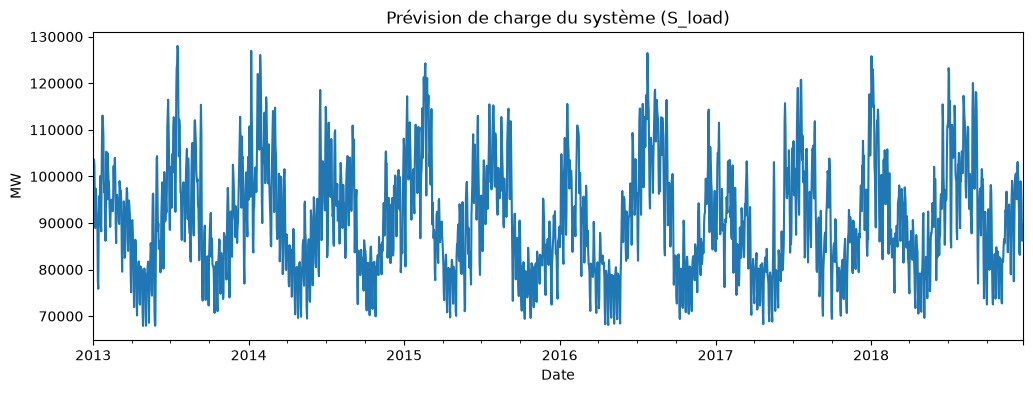

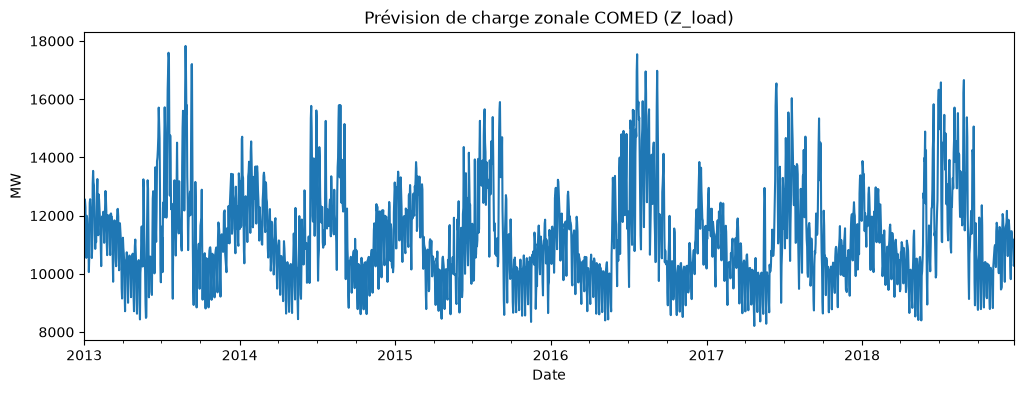

In [957]:
# Un graphique par série, avec un titre et des axes identifiés
daily["price"].plot(figsize=(12, 4), title="Prix zonal COMED (price)")
plt.axhline(100, color="red", linestyle="--")   # ligne à 100 $/MWh
plt.xlabel("Date")
plt.ylabel("$/MWh")
plt.show()

daily["S_load"].plot(figsize=(12, 4), title="Prévision de charge du système (S_load)")
plt.xlabel("Date")
plt.ylabel("MW")
plt.show()

daily["Z_load"].plot(figsize=(12, 4), title="Prévision de charge zonale COMED (Z_load)")
plt.xlabel("Date")
plt.ylabel("MW")
plt.show()

In [958]:
# Garder seulement les jours où le prix moyen est au-dessus de 100
daily[daily["price"] > 100]

,price,S_load,Z_load
date,,,
2013-07-17,102.302668,124129.625000,17023.666667
2014-01-07,181.008104,126952.541667,14709.333333
2014-01-08,173.225953,115987.250000,13384.666667
2014-01-23,204.214823,121922.208333,13851.958333
2014-01-24,119.649783,120698.458333,13718.833333
2014-01-27,134.963949,112050.708333,14200.958333
2014-01-28,456.761566,126056.291667,14548.958333
2014-02-11,172.402591,116980.208333,13695.041667
2014-03-03,129.962363,110206.416667,13147.875000


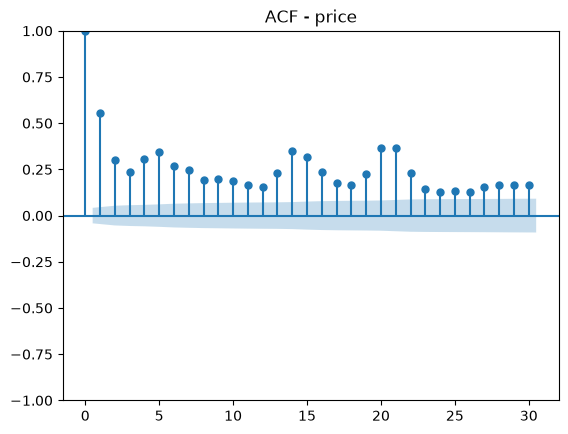

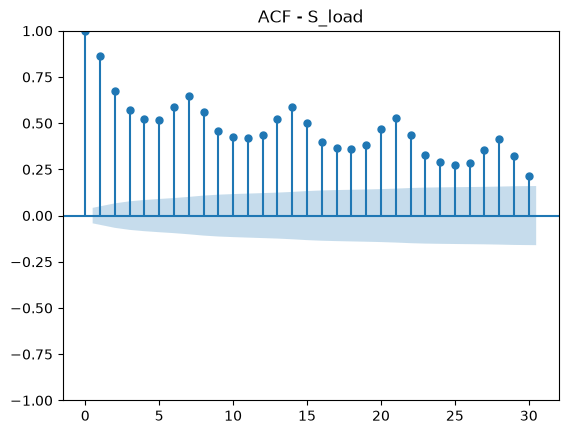

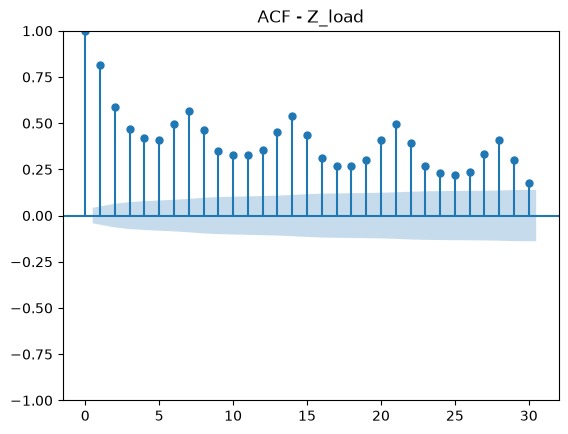

In [959]:
# ACF de chaque série jusqu'à 30 jours de retard.
# Les barres qui sortent de la zone bleue sont significatives.
plot_acf(daily["price"], lags=30, title="ACF - price")
plt.show()

plot_acf(daily["S_load"], lags=30, title="ACF - S_load")
plt.show()

plot_acf(daily["Z_load"], lags=30, title="ACF - Z_load")
plt.show()

In [960]:
# Autocorrélation de chaque série pour les retards 1 à 30
retards = list(range(1, 31))

acf_table = pd.DataFrame({
    "price":  [daily["price"].autocorr(lag=l) for l in retards],
    "S_load": [daily["S_load"].autocorr(lag=l) for l in retards],
    "Z_load": [daily["Z_load"].autocorr(lag=l) for l in retards],
}, index=retards)

acf_table.index.name = "retard"
acf_table.round(2)

,price,S_load,Z_load
retard,,,
1,0.56,0.86,0.82
2,0.30,0.67,0.59
3,0.24,0.57,0.47
4,0.31,0.52,0.42
5,0.35,0.52,0.41
6,0.27,0.59,0.50
7,0.25,0.65,0.57
8,0.19,0.56,0.46
9,0.20,0.46,0.35


In [961]:
# Corrélation entre les deux séries de charge (entre -1 et 1)
print(daily["S_load"].corr(daily["Z_load"]))

0.8583148603531803


b. AIC et BIC

In [962]:
def Q2_AR(y, lag, max_lag=None):
    """
    Estime un modèle AR sur la série y et retourne un objet AutoRegResults.

    y       : une Série pandas
    lag     : un entier positif (ordre du AR) ou 'aic', 'bic', 'hqic'
    max_lag : nombre maximal de retards à tester si lag est un critère (par défaut None)
    """
    # Cas 1 : lag est un entier -> on l'utilise directement comme ordre du AR
    if isinstance(lag, int) and not isinstance(lag, bool):
        if lag < 1:
            raise ValueError("lag doit être un entier positif.")
        return AutoReg(y, lags=lag, trend="c").fit()

    # Cas 2 : lag est un critère d'information -> on choisit l'ordre jusqu'à max_lag
    if isinstance(lag, str) and lag.lower() in ["aic", "bic", "hqic"]:
        if max_lag is None:
            max_lag = int(10 * np.log10(len(y)))   # valeur par défaut si rien n'est donné
        selection = ar_select_order(y, maxlag=max_lag, ic=lag.lower(), trend="c")
        return selection.model.fit()

    # Sinon : valeur non valide
    raise ValueError("lag doit être un entier positif ou 'aic', 'bic', 'hqic'.")

In [963]:
# Les quatre modèles demandés
res_aic = Q2_AR(daily["price"], lag="aic", max_lag=14)
res_bic = Q2_AR(daily["price"], lag="bic", max_lag=14)
res_3   = Q2_AR(daily["price"], lag=3)
res_6   = Q2_AR(daily["price"], lag=6)

# Nombre de retards de chaque modèle
resultats = pd.DataFrame({
    "Modèle": ["Choisi par l'AIC (max 14)", "Choisi par le BIC (max 14)", "AR(3)", "AR(6)"],
    "Nombre de retards": [len(res_aic.ar_lags), len(res_bic.ar_lags), 3, 6],
})
resultats

,Modèle,Nombre de retards
0,Choisi par l'AIC (max 14),14
1,Choisi par le BIC (max 14),14
2,AR(3),3
3,AR(6),6


In [964]:
resultats.round(2).to_excel("resultats_AR.xlsx", index=False)   # enregistrer le tableau en Excel

In [965]:
# Résumé du modèle choisi par l'AIC et le BIC avec 14 retards
print(res_aic.summary())

                            AutoReg Model Results                             
Dep. Variable:                  price   No. Observations:                 2170
Model:                    AutoReg(14)   Log Likelihood               -8401.846
Method:               Conditional MLE   S.D. of innovations             11.622
Date:                Wed, 11 Nov 2026   AIC                          16835.693
Time:                        17:18:01   BIC                          16926.613
Sample:                    01-15-2013   HQIC                         16868.939
                         - 12-24-2018                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.1634      0.896      5.762      0.000       3.407       6.920
price.L1       0.4907      0.021     23.336      0.000       0.449       0.532
price.L2      -0.0584      0.023     -2.486      0.0

In [966]:
# Coefficients clés de l'AR(14), sélectionné par l'AIC et le BIC
retards_cles = ["price.L1", "price.L7", "price.L14"]

coef_cles = pd.DataFrame({
    "Retard": [1, 7, 14],
    "Coefficient": res_aic.params[retards_cles].values,
    "Statistique z": res_aic.tvalues[retards_cles].values,
    "p-value": res_aic.pvalues[retards_cles].values,
})
coef_cles.round(3)

,Retard,Coefficient,Statistique z,p-value
0,1,0.491,23.336,0.0
1,7,0.095,3.978,0.0
2,14,0.202,9.591,0.0


In [967]:
coef_cles.round(3).to_excel("coefficients_AR14.xlsx", index=False)   # enregistrer en Excel

In [968]:
# Autocorrélation du prix au retard 7
print("Autocorrélation de price au retard 7 :", round(daily["price"].autocorr(lag=7), 3))

# Autocorrélation qui reste dans les erreurs (résidus) des AR(3) et AR(6)
print("AR(3) | résidus, retard 7 :", round(res_3.resid.autocorr(lag=7), 3),
      "| retard 14 :", round(res_3.resid.autocorr(lag=14), 3))
print("AR(6) | résidus, retard 7 :", round(res_6.resid.autocorr(lag=7), 3),
      "| retard 14 :", round(res_6.resid.autocorr(lag=14), 3))

# Autocorrélation qui reste dans les erreurs de l'AR(14)
print("AR(14) | résidus, retard 7 :", round(res_aic.resid.autocorr(lag=7), 3),
      "| retard 14 :", round(res_aic.resid.autocorr(lag=14), 3))

Autocorrélation de price au retard 7 : 0.245
AR(3) | résidus, retard 7 : 0.095 | retard 14 : 0.221
AR(6) | résidus, retard 7 : 0.08 | retard 14 : 0.209
AR(14) | résidus, retard 7 : -0.043 | retard 14 : -0.007


c. Prévisions hors échantillon

In [969]:
def Q2_Forecast(res, hmax):
    """
    Retourne un tableau 1-D de prévisions hors échantillon pour les hmax prochaines périodes.

    res  : un objet AutoRegResults (un modèle AR estimé)
    hmax : un entier positif (nombre de jours à prévoir)
    """
    if not isinstance(hmax, int) or hmax < 1:
        raise ValueError("hmax doit être un entier positif.")
    return np.asarray(res.forecast(steps=hmax))

30.504544309711196


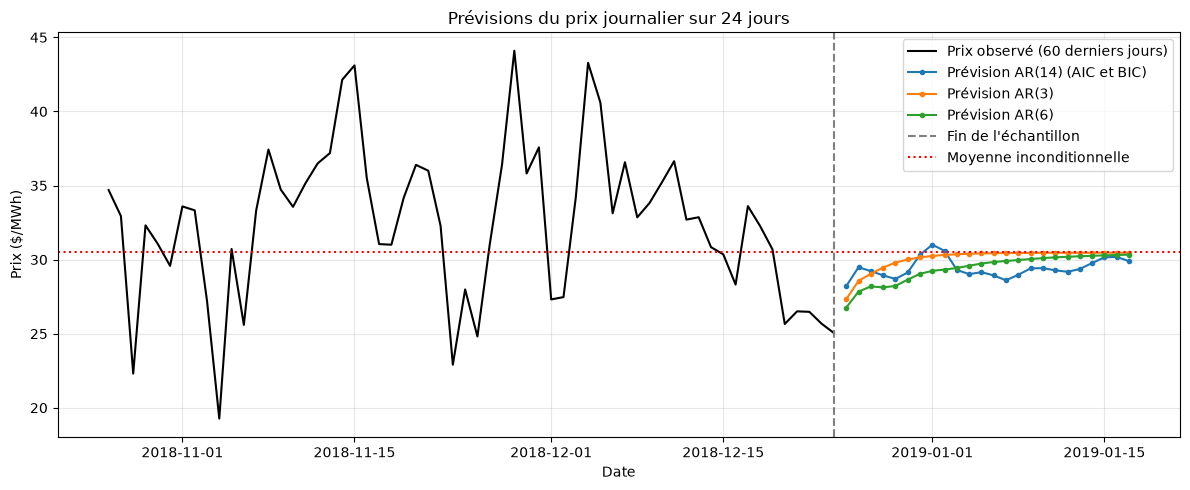

In [970]:
hmax = 24

# Prévisions des modèles de la partie (b)
# (l'AIC et le BIC ont choisi le même AR(14), donc une seule courbe pour les deux)
prev_14 = Q2_Forecast(res_aic, hmax)
prev_3  = Q2_Forecast(res_3, hmax)
prev_6  = Q2_Forecast(res_6, hmax)

# Moyenne inconditionnelle de l'AR(14) : constante / (1 - somme des coefficients)
moyenne = res_aic.params.iloc[0] / (1 - res_aic.params.iloc[1:].sum())
print(moyenne)

# Les 60 derniers jours de données et les dates des 24 jours prévus
derniers_60 = daily["price"].iloc[-60:]
dates_prev = pd.date_range(daily.index[-1] + pd.Timedelta(days=1), periods=hmax, freq="D")

plt.figure(figsize=(12, 5))
plt.plot(derniers_60.index, derniers_60, color="black", label="Prix observé (60 derniers jours)")
plt.plot(dates_prev, prev_14, marker=".", label="Prévision AR(14) (AIC et BIC)")
plt.plot(dates_prev, prev_3, marker=".", label="Prévision AR(3)")
plt.plot(dates_prev, prev_6, marker=".", label="Prévision AR(6)")
plt.axvline(daily.index[-1], color="gray", linestyle="--", label="Fin de l'échantillon")
plt.axhline(moyenne, color="red", linestyle=":", label="Moyenne inconditionnelle")
plt.title("Prévisions du prix journalier sur 24 jours")
plt.xlabel("Date")
plt.ylabel("Prix ($/MWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [971]:
# Prévisions de chaque modèle à quelques horizons
tableau_prev = pd.DataFrame({
    "Horizon (jours)": [1, 3, 7, 14, 24],
    "AR(3)":  prev_3[[0, 2, 6, 13, 23]],
    "AR(6)":  prev_6[[0, 2, 6, 13, 23]],
    "AR(14)": prev_14[[0, 2, 6, 13, 23]],
})
print(tableau_prev.round(1))

# Moyenne inconditionnelle de chaque modèle
print("Moyenne inconditionnelle AR(3)  :", round(res_3.params.iloc[0] / (1 - res_3.params.iloc[1:].sum()), 2))
print("Moyenne inconditionnelle AR(6)  :", round(res_6.params.iloc[0] / (1 - res_6.params.iloc[1:].sum()), 2))
print("Moyenne inconditionnelle AR(14) :", round(moyenne, 2))

   Horizon (jours)  AR(3)  AR(6)  AR(14)
0                1   27.3   26.8    28.2
1                3   29.0   28.2    29.2
2                7   30.1   29.0    30.3
3               14   30.4   29.9    28.6
4               24   30.5   30.3    29.9
Moyenne inconditionnelle AR(3)  : 30.46
Moyenne inconditionnelle AR(6)  : 30.47
Moyenne inconditionnelle AR(14) : 30.5


In [972]:
tableau_prev.loc[len(tableau_prev)] = ["Moyenne inconditionnelle",
    res_3.params.iloc[0] / (1 - res_3.params.iloc[1:].sum()),
    res_6.params.iloc[0] / (1 - res_6.params.iloc[1:].sum()),
    moyenne]
tableau_prev.round(2).to_excel("previsions_AR.xlsx", index=False)

/var/folders/1c/2wnr9rqj01bb6k9cj7gg8q5r0000gn/T/ipykernel_68550/2287769440.py:1: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  tableau_prev.loc[len(tableau_prev)] = ["Moyenne inconditionnelle",


In [973]:
daily["price"].iloc[-1]

np.float64(25.044461666666667)

d. Fenêtres glissantes

In [974]:
def Q2_PrevRoul(s, T0, p, h):
    """
    Prévisions glissantes avec un AR(p) estimé sur une fenêtre de taille fixe T0.

    s  : un tableau 1-D (la série)
    T0 : taille de la fenêtre d'estimation
    p  : nombre de retards du AR
    h  : nombre de périodes à prévoir à chaque fenêtre

    Retourne un tableau 2-D de forme (nombre de fenêtres, h) :
    la ligne i contient les h prévisions faites à partir de la fenêtre i,
    la colonne k contient toutes les prévisions à k+1 pas.
    """
    s = np.asarray(s, dtype=float)

    # La première fenêtre va de 0 à T0-1, la dernière se termine à la dernière observation
    nb_fenetres = len(s) - T0 + 1
    previsions = np.zeros((nb_fenetres, h))

    for i in range(nb_fenetres):
        fenetre = s[i : i + T0]                             # T0 observations, décalées de i
        res = AutoReg(fenetre, lags=p, trend="c").fit()     # estimer l'AR(p)
        previsions[i, :] = res.forecast(steps=h)            # stocker les h prévisions

    return previsions

In [975]:
prev_roul_3 = Q2_PrevRoul(daily["price"], T0=300, p=3, h=24)
prev_roul_6 = Q2_PrevRoul(daily["price"], T0=300, p=6, h=24)

print("AR(3) : forme du tableau =", prev_roul_3.shape)
print("AR(6) : forme du tableau =", prev_roul_6.shape)
print("Nombre de fenêtres glissantes :", prev_roul_3.shape[0])

AR(3) : forme du tableau = (1885, 24)
AR(6) : forme du tableau = (1885, 24)
Nombre de fenêtres glissantes : 1885


e. Test DM

In [976]:
def Q2_DM(d, h):
    """
    Statistique du test de Diebold-Mariano.

    d : tableau 1-D des différentiels de perte (erreur² du modèle 1 - erreur² du modèle 2)
    h : horizon de prévision (les erreurs à h pas sont autocorrélées jusqu'au retard h-1)
    """
    d = np.asarray(d, dtype=float)
    T = len(d)
    d_moy = d.mean()
    d_c = d - d_moy

    # Variance de long terme : variance + 2 x autocovariances jusqu'au retard h-1
    variance_lt = np.sum(d_c ** 2) / T
    for k in range(1, h):
        variance_lt += 2 * np.sum(d_c[k:] * d_c[:-k]) / T

    # Si elle est négative (rare), on utilise des poids de Bartlett (Newey-West)
    if variance_lt <= 0:
        variance_lt = np.sum(d_c ** 2) / T
        for k in range(1, h):
            variance_lt += 2 * (1 - k / h) * np.sum(d_c[k:] * d_c[:-k]) / T

    return d_moy / np.sqrt(variance_lt / T)

In [977]:
s = daily["price"].to_numpy()
T0 = 300
lignes = []

for h in range(1, 25):
    # Nombre de prévisions à h pas dont on connaît le vrai prix
    n_prev = len(s) - T0 - h + 1

    # Vrais prix correspondant aux prévisions à h pas
    reel = s[T0 - 1 + h : T0 - 1 + h + n_prev]

    # Erreurs de prévision de chaque modèle
    erreur_3 = reel - prev_roul_3[:n_prev, h - 1]
    erreur_6 = reel - prev_roul_6[:n_prev, h - 1]

    # Différentiel de perte : erreur² AR(3) - erreur² AR(6)
    d = erreur_3 ** 2 - erreur_6 ** 2

    dm = Q2_DM(d, h)
    p_value = 2 * (1 - norm.cdf(abs(dm)))   # p-value bilatérale
    lignes.append([h, n_prev, np.mean(erreur_3 ** 2), np.mean(erreur_6 ** 2), dm, p_value])

resultats_dm = pd.DataFrame(lignes, columns=["Horizon", "Nb prévisions", "EQM AR(3)",
                                             "EQM AR(6)", "Statistique DM", "p-value"])
resultats_dm.round(3)

,Horizon,Nb prévisions,EQM AR(3),EQM AR(6),Statistique DM,p-value
0,1,1884,294.553,386.115,-0.870,0.384
1,2,1883,329.556,399.830,-0.610,0.542
2,3,1882,287.849,329.786,-0.746,0.455
3,4,1881,266.063,345.356,-0.919,0.358
4,5,1880,267.278,301.757,-0.886,0.375
5,6,1879,271.025,627.603,-1.000,0.318
6,7,1878,271.629,612.942,-0.991,0.322
7,8,1877,262.672,414.626,-0.990,0.322
8,9,1876,246.747,411.164,-0.988,0.323
9,10,1875,251.104,345.595,-0.986,0.324


In [978]:
resultats_dm.round(3).to_excel("resultats_DM.xlsx", index=False)   # enregistrer en Excel

In [979]:
# Position de la plus grande prévision de l'AR(6) dans le tableau (fenêtre, horizon)
i, k = np.unravel_index(np.argmax(prev_roul_6), prev_roul_6.shape)

fin_fenetre = daily.index[300 - 1 + i]                 # dernier jour de la fenêtre
jour_prevu  = daily.index[300 - 1 + i + k + 1]         # jour visé par la prévision

print("Fenêtre se terminant le :", fin_fenetre.date())
print("Horizon :", k + 1, "jours")
print("Prévision AR(6) :", round(prev_roul_6[i, k], 1), "$/MWh")
print("Vrai prix ce jour-là :", round(daily["price"].loc[jour_prevu], 2), "$/MWh")

Fenêtre se terminant le : 2014-01-28
Horizon : 24 jours
Prévision AR(6) : 1758.0 $/MWh
Vrai prix ce jour-là : 44.17 $/MWh


f. Test d'engloblement de prévision

In [980]:
s = daily["price"].to_numpy()
T0 = 300
dm_engl = {}

for h in range(1, 25):
    n_prev = len(s) - T0 - h + 1
    reel = s[T0 - 1 + h : T0 - 1 + h + n_prev]

    # Erreurs de prévision de chaque modèle (prévisions glissantes de la partie d)
    erreur_3 = reel - prev_roul_3[:n_prev, h - 1]
    erreur_6 = reel - prev_roul_6[:n_prev, h - 1]

    # Différentiel de perte du test d'englobement
    d = erreur_3 * (erreur_3 - erreur_6)

    dm = Q2_DM(d, h)
    p_value = 1 - norm.cdf(dm)          # p-value unilatérale (H1 : AR(6) n'est pas englobé)
    dm_engl[h] = [dm, p_value]

# DataFrame : lignes = statistique DM et p-value, colonnes = horizons
resultats_engl = pd.DataFrame(dm_engl, index=["Statistique DM", "p-value"])
resultats_engl.columns.name = "Horizon"
resultats_engl.T.round(3)

,Statistique DM,p-value
Horizon,,
1,1.305,0.096
2,1.158,0.123
3,1.329,0.092
4,1.318,0.094
5,-0.434,0.668
6,-0.885,0.812
7,-0.850,0.802
8,-0.634,0.737
9,1.225,0.110


In [ ]:
resultats_engl.T.round(3).to_excel("resultats_englobement.xlsx")